<a href="https://colab.research.google.com/github/emlluc/Data201-lab/blob/main/Week_9_homework.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 Homework: Decision Trees

### Part 1: Build the Tree

In [26]:
%pip -q install ISLP

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ISLP import load_data

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

#plt.rcParams['figure.dpi'] = 100

In [28]:
from ISLP import load_data
carseats = load_data('Carseats')

carseats.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [29]:
# 1.2
# Convert Sales to binary (HighSales = 1 if Sales > 8, else 0)
carseats['HighSales'] = (carseats['Sales'] > 8).astype(int)
carseats = carseats.drop(columns=['Sales'])

# One-hot encode categorical predictors
X = pd.get_dummies(carseats.drop(columns='HighSales'), columns=['ShelveLoc', 'Urban', 'US']).astype(int)
y = carseats['HighSales']

# 1.3
# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)


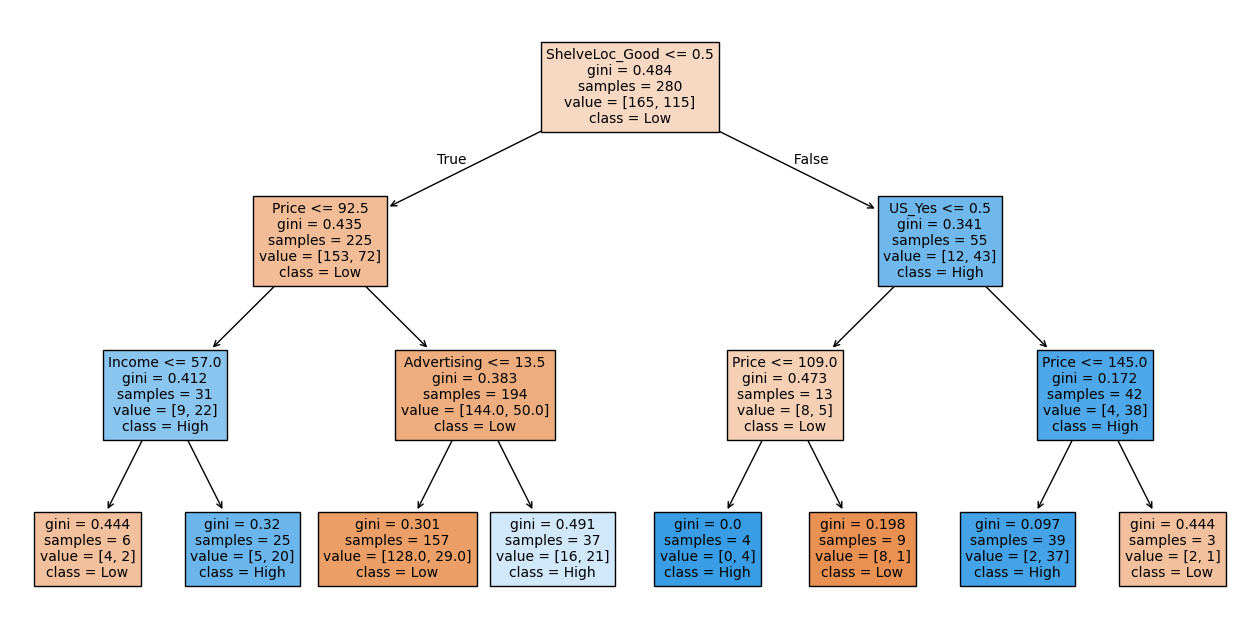

Train accuracy: 0.8
Test accuracy:  0.8


In [30]:
# 1.4
# Train a DecisionTreeClassifier with max_depth=3
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

# 1.5
# Plot the tree
plt.figure(figsize=(16, 8))
plot_tree(tree,
          feature_names=list(X.columns),
          class_names=['Low', 'High'],
          filled=True,
          fontsize=10)
plt.show()

# Report training and test accuracy
print('Train accuracy:', round(tree.score(X_train, y_train), 3))
print('Test accuracy: ', round(tree.score(X_test, y_test), 3))

### Part 2: Handle Overfitting

In [31]:
full = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print('Depth:', full.get_depth(), '  Leaves:', full.get_n_leaves())
print('Train accuracy:', round(full.score(X_train, y_train), 3))
print('Test accuracy: ', round(full.score(X_test, y_test), 3))

Depth: 10   Leaves: 55
Train accuracy: 1.0
Test accuracy:  0.792


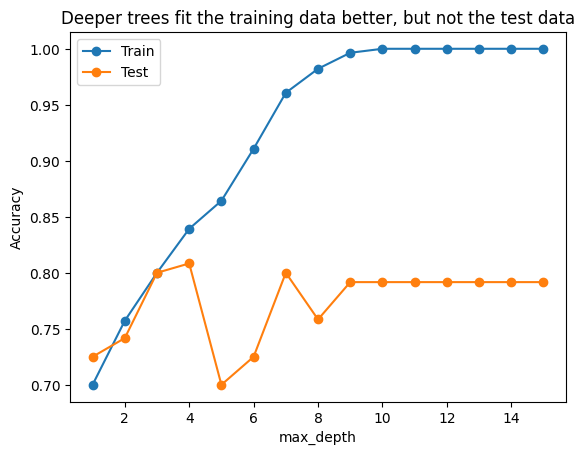

In [32]:
# 2.3
# Train vs. test accuracy as the tree is allowed to grow deeper
depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

plt.plot(depths, train_acc, marker='o', label='Train')
plt.plot(depths, test_acc, marker='o', label='Test')
plt.xlabel('max_depth'); plt.ylabel('Accuracy'); plt.legend()
plt.title('Deeper trees fit the training data better, but not the test data')
plt.show()

In [33]:
# 2.4
grid = GridSearchCV(
    DecisionTreeClassifier(random_state=0),
    param_grid={'max_depth': [1, 2, 3, 4, 5, 6, 8, 10],
                'min_samples_leaf': [1, 5, 10, 20]},
    cv=5)

grid.fit(X_train, y_train)

print('Best settings:', grid.best_params_)
print('Best CV accuracy:', round(grid.best_score_, 3))
print('Test accuracy of best model:', round(grid.score(X_test, y_test), 3))
# max depth = 6 is the best, with accuracy of 72.5%

Best settings: {'max_depth': 6, 'min_samples_leaf': 1}
Best CV accuracy: 0.754
Test accuracy of best model: 0.725


In [34]:
# 2.5
final_tree = DecisionTreeClassifier(max_depth=6, random_state=0)

final_tree.fit(X_train,y_train)

print('Testing accuracy with depth 6:', final_tree.score(X_test,y_test))

Testing accuracy with depth 6: 0.725


In [35]:
# final tree
print(export_text(final_tree, feature_names=list(X.columns)))

|--- ShelveLoc_Good <= 0.50
|   |--- Price <= 92.50
|   |   |--- Income <= 57.00
|   |   |   |--- ShelveLoc_Medium <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- ShelveLoc_Medium >  0.50
|   |   |   |   |--- class: 1
|   |   |--- Income >  57.00
|   |   |   |--- Price <= 82.00
|   |   |   |   |--- class: 1
|   |   |   |--- Price >  82.00
|   |   |   |   |--- Age <= 65.00
|   |   |   |   |   |--- CompPrice <= 103.00
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- CompPrice >  103.00
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- Age >  65.00
|   |   |   |   |   |--- class: 0
|   |--- Price >  92.50
|   |   |--- Advertising <= 13.50
|   |   |   |--- Age <= 47.50
|   |   |   |   |--- ShelveLoc_Medium <= 0.50
|   |   |   |   |   |--- Price <= 100.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- Price >  100.50
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- ShelveLoc_Medium >  0.50
|   |   |   |   |   |--- Price <= 142.50
|   |

### Part 3: Answering Questions

Interpreting the tree: ShelveLoc_good was the best chosen predictor for the first split. This means that this variable had the best comparable split/this split had the greatest impurity.

Choosing tree depth: The best performing depth was 6, at an accuracy of 72.5%. It is important to use cv over test accuracy for depth because we only want to handle the training data. Manipulating the test set introduces bias to the results.

Overfitting: Increasing tree depth doesn't always improve cv accuracy. In the graph, the accuracy dips after surpassing a depth of 6. We want to find the "sweet spot", where accuracy is high without bringing up the depth too much.


### Wrap-Up Questions


What does a leaf predict in a classification tree? In a regression tree?
Why did the full tree reach 100% training accuracy but do worse on the test set?

A leaf in a classification tree finds the majority class (most common variable in the training sample). In a regression tree, the leaf predicts the target value of the training samples. However, the full tree overfit the training data; it was too strict on the training samples in terms of purity.


Give two ways to limit tree complexity. Which one did cross-validation help you tune?

1. Making the max_depth smaller, and creating a minimum sample about for the leaf nodes
2. Cv helped tune the first one by finding the best possible max depth (6).

Why do we not need to scale features before fitting a tree?

Each split/decision that a tree makes is independent of the other features. Therefore, the variables don't need to be scaled to fit eachother.

A teammate says "Age has importance 0, so it is irrelevant to heart disease." What is wrong with that claim? (answer in terms of reducing impurity)

Age having an importance of 0 more suggests that it was highly correlated with another variables. The tree would've chosen that variable over age because it had a higher purity, and left it with an importance of 0.

Name one strength and one weakness of a single decision tree that you saw in this lab.

Although the tree is very readable and the data is straightfoward (no need for scaling, etc), the data has high variance, which made the test accuracy of the model slightly unstable (the max depth between 4-8 is irregular).
